In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../'))
sys.path.append(base_path)

import numpy as np
import matplotlib.pyplot as plt  
import pandas as pd
from IPython.display import display


import project_images_loader as pil
import utils.util as util
import utils.functions as fc
import utils.nifti_functions as nfc
import dfield_applier as dfield_applier
import constants as cts



### Load images

In [2]:
id = pil.get_matching_ids()[304]
%matplotlib widget


img_moving_path_name = pil.get_registered_to_template_image_path_name(3, id, pil.REGISTRATION_TO_MNI, absolute=True)
# mask_moving_path_name = pil.get_brain_mask_path_name(3, id, pil.REGISTRATION_TO_MNI, absolute=True)
mask_moving_path_name = pil.get_segmentation_path_name(3, id, simple=False, absolute=True)

dfield_path_name = cts.get_image_path_name(id, cts.PFILE_0038, cts.INAME_DFIELD)


# load images and masks
img_moving, _ = nfc.load_nifti(img_moving_path_name)
mask_moving, _ = nfc.load_nifti(mask_moving_path_name)

img_fixed, _ = nfc.load_nifti(pil.get_registered_to_template_image_path_name(4, id, pil.REGISTRATION_TO_MNI, absolute=True))
# mask_fixed, a_ff = nfc.load_nifti(pil.get_brain_mask_path_name(4, id, pil.REGISTRATION_TO_MNI, absolute=True))
mask_fixed, _ = nfc.load_nifti(pil.get_segmentation_path_name(4, id, simple=False, absolute=True))

img_registed, _ = nfc.load_nifti(cts.get_image_path_name(id, cts.PFILE_0038, cts.INAME_REGISTERED))
# mask_registed, _ = nfc.load_nifti(cts.get_image_path_name(id, cts.PFILE_0038, cts.INAME_MASK_REGISTERED))
mask_registed, _ = nfc.load_nifti(cts.get_image_path_name(id, cts.PFILE_0038, cts.INAME_SEG_REGISTERED))

dfield, aff_dfield = nfc.load_nifti(dfield_path_name)
dfield = dfield[:,:,:,0].astype(np.float32)


img_moving = util.skull_stripping_and_normalize(img_moving, mask_moving) # R
img_fixed = util.skull_stripping_and_normalize(img_fixed, mask_fixed) # G
img_registed = util.skull_stripping_and_normalize(img_registed, mask_registed) # B



In [3]:

img_reg_elastix = dfield_applier.apply_deformation_field_elastix(img_moving_path_name, dfield_path_name)
mask_reg_elastix = dfield_applier.apply_deformation_field_elastix(mask_moving_path_name, dfield_path_name, binary=True)

img_reg_voxelmorph = dfield_applier.apply_deformation_field_voxelmorph(img_moving, dfield)
mask_reg_voxelmorph = dfield_applier.apply_deformation_field_voxelmorph(mask_moving, dfield, binary=True)

img_reg_mappingc = dfield_applier.apply_deformation_field_mapping_coords(img_moving, dfield)
mask_reg_mappingc = dfield_applier.apply_deformation_field_mapping_coords(mask_moving, dfield, binary=True)

img_reg_elastix = util.skull_stripping_and_normalize(img_reg_elastix, mask_reg_elastix)
img_reg_voxelmorph = util.skull_stripping_and_normalize(img_reg_voxelmorph, mask_reg_voxelmorph)
img_reg_mappingc = util.skull_stripping_and_normalize(img_reg_mappingc, mask_reg_mappingc)


In [4]:

metrisc_original = util.get_metrics_dict(img_moving, img_fixed)
metrisc_expected = util.get_metrics_dict(img_registed, img_fixed)

metrisc_difference_elastix = util.get_metrics_dict(img_registed, img_reg_elastix)
metrisc_difference_vmx = util.get_metrics_dict(img_registed, img_reg_voxelmorph)
metrisc_difference_mappingc = util.get_metrics_dict(img_registed, img_reg_mappingc)

metrics_elastix = util.get_metrics_dict(img_fixed, img_reg_elastix)
metrics_vmx = util.get_metrics_dict(img_fixed, img_reg_voxelmorph)
metrics_mappingc = util.get_metrics_dict(img_fixed, img_reg_mappingc)

dice_expected = util.compute_multiple_dice_coefficients(mask_moving, mask_registed)
dice_elastix = util.compute_multiple_dice_coefficients(mask_moving, mask_reg_elastix)
dice_vmx = util.compute_multiple_dice_coefficients(mask_moving, mask_reg_voxelmorph)
dice_mappingc = util.compute_multiple_dice_coefficients(mask_moving, mask_reg_mappingc)

print("Original:\n",metrisc_original)
print("Expected:\n",metrisc_expected)

print("Difference Elastix:\n",metrisc_difference_elastix)
print("Difference Voxelmorph:\n",metrisc_difference_vmx)
print("Difference Mapping coords:\n",metrisc_difference_mappingc)

print("Obtained Elastix:\n",metrics_elastix)
print("Obtained Voxelmorph:\n",metrics_vmx)
print("Obtained Mapping coords:\n",metrics_mappingc)




df = pd.DataFrame([dice_expected, dice_elastix, dice_vmx, dice_mappingc])
display(df.head(10))

df_stats = pd.DataFrame({
    'min': df.min(axis=1),
    'max': df.max(axis=1),
    'mean': df.mean(axis=1)
})

display(df_stats.head(10))



# Original:
#  {'rms': 1.5533802997542593e-05, 'ncc': 0.9692839054151932, 'mi': 0.7136996426673754, 'ssim': 0.9496735159032365}
# Expected:
#  {'rms': 1.1341584528452558e-05, 'ncc': 0.9859208854808492, 'mi': 0.9011961971284874, 'ssim': 0.9735859693526735}
# Difference Elastix:
#  {'rms': 1.4579059290932102e-05, 'ncc': 0.9998157411659165, 'mi': 1.1719670441606294, 'ssim': 0.966597200383389}
# Difference Voxelmorph:
#  {'rms': 8.659462419893742e-05, 'ncc': 0.8283922028968597, 'mi': 0.6768625631418028, 'ssim': 0.1381719861197522}
# Difference Mapping coords:
#  {'rms': 8.659398951054155e-05, 'ncc': 0.8283939742557885, 'mi': 0.6768615074617879, 'ssim': 0.13817137456481482}
# Obtained Elastix:
#  {'rms': 1.3994280909011088e-05, 'ncc': 0.9858553831515416, 'mi': 0.9137537150909139, 'ssim': 0.9612774399930623}
# Obtained Voxelmorph:
#  {'rms': 9.642178537431108e-05, 'ncc': 0.8256801791169956, 'mi': 0.6503315283778832, 'ssim': 0.13702492619938614}
# Obtained Mapping coords:
#  {'rms': 9.64211316350062e-05, 'ncc': 0.8256818564789126, 'mi': 0.6503307847639412, 'ssim': 0.13702437007243373}

# 0.0	2.0	4.0	5.0	7.0	8.0	10.0	11.0	12.0	13.0	...	2024.0	2025.0	2026.0	2027.0	2028.0	2029.0	2030.0	2031.0	2034.0	2035.0
# 0	0.992646	0.903479	0.864483	0.748457	0.864848	0.882742	0.914422	0.894366	0.888093	0.858549	...	0.831222	0.919031	0.678920	0.785459	0.764888	0.868477	0.710929	0.844866	0.656655	0.775503
# 1	0.992646	0.903477	0.864483	0.748457	0.864848	0.882734	0.914422	0.894366	0.888093	0.858549	...	0.831162	0.919031	0.678920	0.785459	0.764870	0.868477	0.710929	0.844866	0.656655	0.775503
# 2	0.993437	0.907535	0.861074	0.684844	0.848236	0.885415	0.927486	0.861765	0.892654	0.861970	...	0.829140	0.919915	0.739528	0.781824	0.763250	0.869570	0.769466	0.845885	0.663442	0.789828
# 3	0.993437	0.907535	0.861074	0.684844	0.848236	0.885415	0.927486	0.861765	0.892654	0.861970	...	0.829182	0.919915	0.739528	0.781824	0.763250	0.869570	0.769466	0.845885	0.663442	0.789828
# 4 rows × 96 columns

# min	max	mean
# 0	0.108159	0.992646	0.804285
# 1	0.108159	0.992646	0.804285
# 2	0.244024	0.993437	0.811666
# 3	0.244024	0.993437	0.811666


Original:
 {'rms': 1.5300139323532443e-05, 'ncc': 0.9645559710730833, 'mi': 0.7091889354582039, 'ssim': 0.9509716506030071}
Expected:
 {'rms': 1.0536677272384575e-05, 'ncc': 0.9840276567725127, 'mi': 0.8671461806290224, 'ssim': 0.9727750493874172}
Difference Elastix:
 {'rms': 2.5566915490121155e-12, 'ncc': 0.9999999999999992, 'mi': 1.5686192110493586, 'ssim': 0.9999999999999964}
Difference Voxelmorph:
 {'rms': 9.26774137081048e-05, 'ncc': 0.8368664759217673, 'mi': 0.7477076237348608, 'ssim': 0.16228311970702175}
Difference Mapping coords:
 {'rms': 9.267736115058992e-05, 'ncc': 0.836867229032698, 'mi': 0.7477084993730951, 'ssim': 0.16228304294645785}
Obtained Elastix:
 {'rms': 1.0536677704070405e-05, 'ncc': 0.9840276567763336, 'mi': 0.8671462574105622, 'ssim': 0.9727750473935421}
Obtained Voxelmorph:
 {'rms': 0.00010268066992506039, 'ncc': 0.8258310258004941, 'mi': 0.6844411146601348, 'ssim': 0.15049176427489927}
Obtained Mapping coords:
 {'rms': 0.00010268059825903742, 'ncc': 0.8258313

,0.0,2.0,4.0,5.0,7.0,8.0,10.0,11.0,12.0,13.0,...,2024.0,2025.0,2026.0,2027.0,2028.0,2029.0,2030.0,2031.0,2034.0,2035.0
0,0.993988,0.917031,0.791015,0.734238,0.949507,0.953858,0.880935,0.803053,0.928414,0.872303,...,0.743835,0.968866,0.790732,0.592810,0.741944,0.879754,0.912232,0.834334,0.713311,0.887258
1,0.993988,0.917031,0.791015,0.734238,0.949507,0.953858,0.880935,0.803053,0.928414,0.872303,...,0.743835,0.968866,0.790732,0.592810,0.741944,0.879754,0.912232,0.834334,0.713311,0.887258
2,0.994598,0.924088,0.791009,0.731458,0.945327,0.958108,0.915888,0.754193,0.925207,0.889048,...,0.796336,0.970253,0.801456,0.685804,0.751915,0.884813,0.917490,0.830889,0.703204,0.884429
3,0.994598,0.924090,0.791009,0.731458,0.945327,0.958108,0.915888,0.754193,0.925207,0.889048,...,0.796336,0.970196,0.801456,0.685804,0.751915,0.884813,0.917461,0.830889,0.703204,0.884429


,min,max,mean
0,0.107453,0.993988,0.831843
1,0.107453,0.993988,0.831843
2,0.242960,0.994598,0.842878
3,0.242960,0.994598,0.842876


### VIsualize images

-59099.87797205419
-59099.929269669134
-0.051297614589547305


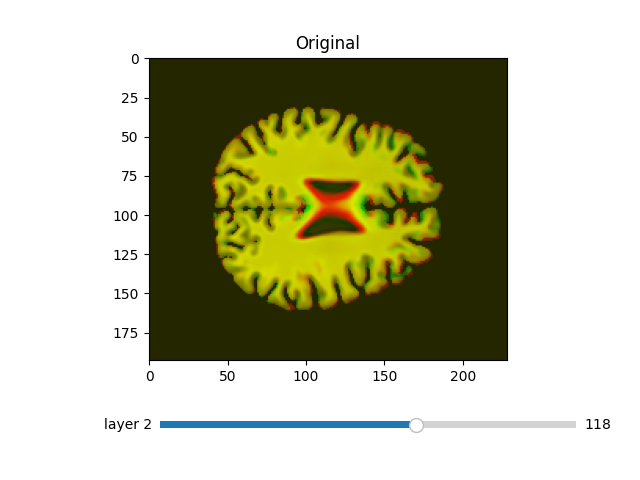

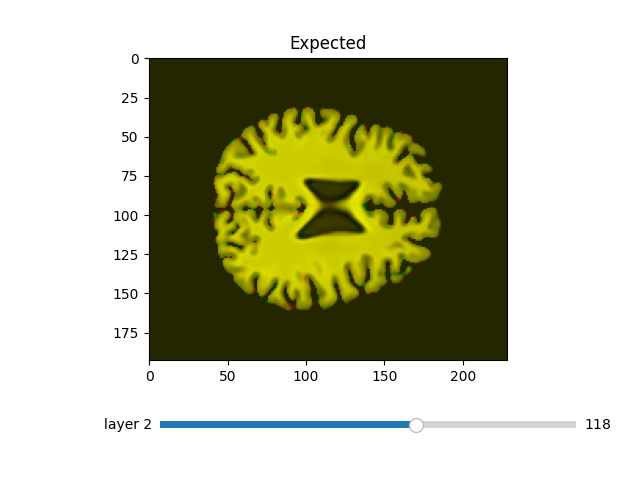

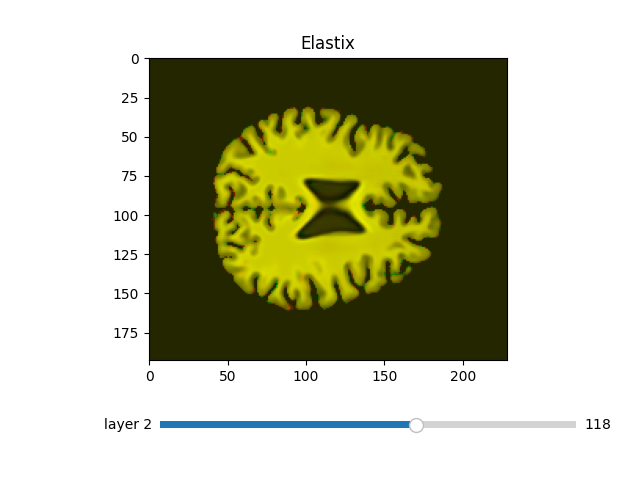

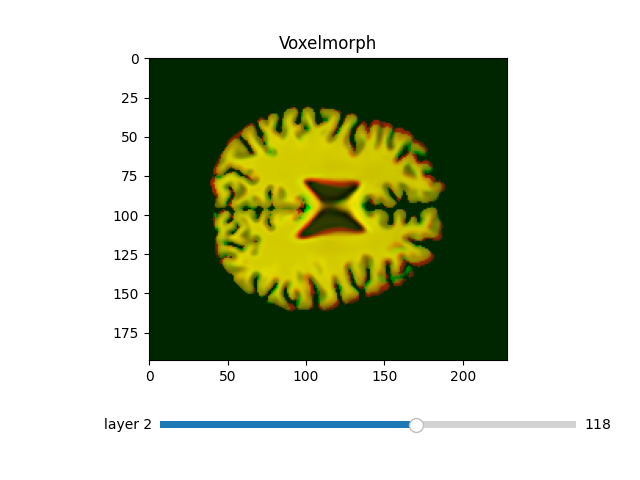

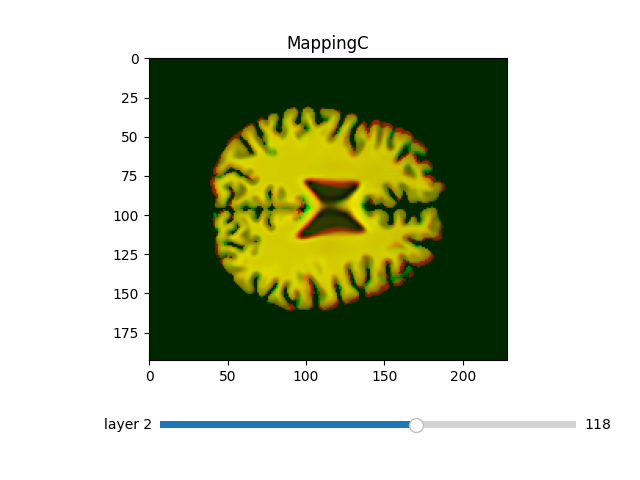

In [5]:
%matplotlib widget

img_rgb_original = np.stack((img_moving, img_fixed, np.zeros_like(img_fixed)), axis=3)
img_rgb_expected = np.stack((img_registed, img_fixed, np.zeros_like(img_fixed)), axis=3)
img_rgb_elastix = np.stack((img_reg_elastix, img_fixed, np.zeros_like(img_fixed)), axis=3)
img_rgb_vmx = np.stack((img_reg_voxelmorph, img_fixed, np.zeros_like(img_fixed)), axis=3)
img_rgb_mappingc = np.stack((img_reg_mappingc, img_fixed, np.zeros_like(img_fixed)), axis=3)

print(np.sum(img_registed-img_fixed))
print(np.sum(img_reg_elastix-img_fixed))
print(np.sum(img_reg_elastix-img_registed))

fc.imgshow_3D("Original", img_rgb_original, current_plane=118)
fc.imgshow_3D("Expected", img_rgb_expected, current_plane=118)
fc.imgshow_3D("Elastix", img_rgb_elastix, current_plane=118)
fc.imgshow_3D("Voxelmorph", img_rgb_vmx, current_plane=118)
fc.imgshow_3D("MappingC", img_rgb_mappingc, current_plane=118)



### Visualize segmentation

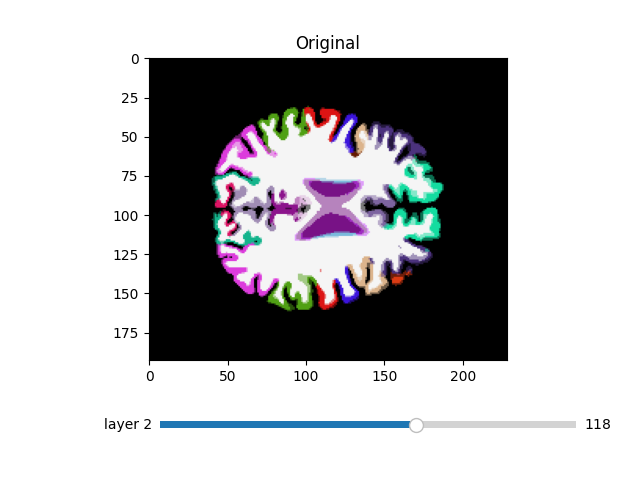

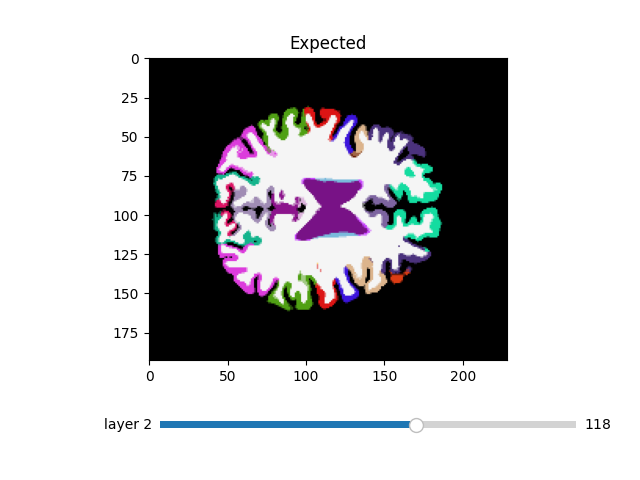

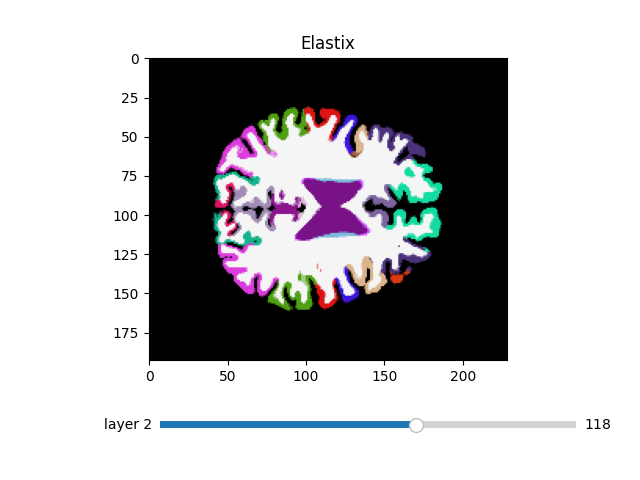

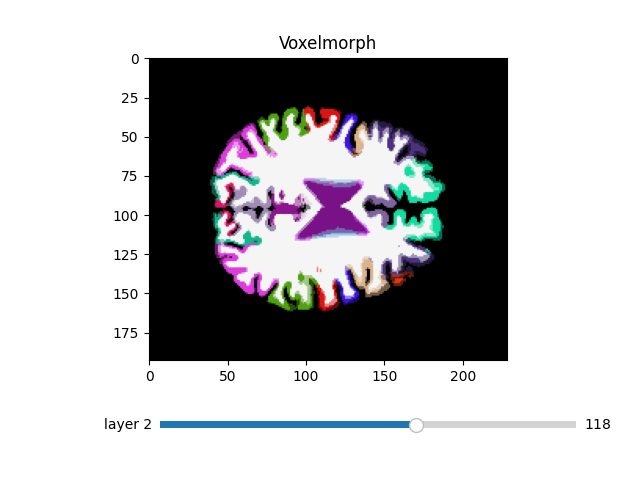

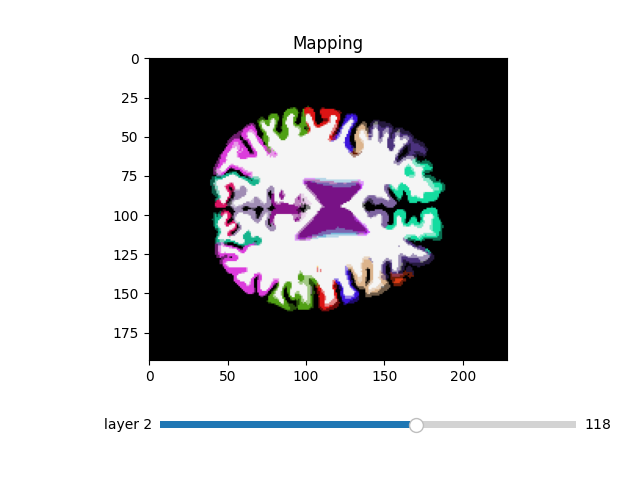

In [6]:
import utils.util_freesurfer_segmentation as util_freesurfer

mask_fixed_rgb = util_freesurfer.seg_to_rgbseg(mask_fixed).astype(np.float32)
mask_moving_rgb = util_freesurfer.seg_to_rgbseg(mask_moving).astype(np.float32)

mask_expected_rgb = util_freesurfer.seg_to_rgbseg(mask_registed).astype(np.float32)
mask_reg_elastix_rgb = util_freesurfer.seg_to_rgbseg(mask_reg_elastix).astype(np.float32)
mask_reg_vmx_rgb = util_freesurfer.seg_to_rgbseg(mask_reg_voxelmorph).astype(np.float32)
mask_reg_mappingc_rgb = util_freesurfer.seg_to_rgbseg(mask_reg_mappingc).astype(np.float32)

overlap_original = ((mask_moving_rgb + mask_fixed_rgb) / 2).astype(np.uint8)
overlap_expected = ((mask_expected_rgb + mask_fixed_rgb) / 2).astype(np.uint8)
overlap_elastix = ((mask_reg_elastix_rgb + mask_fixed_rgb) / 2).astype(np.uint8)
overlap_vmx = ((mask_reg_vmx_rgb + mask_fixed_rgb) / 2).astype(np.uint8)
overlap_mappingc = ((mask_reg_mappingc_rgb + mask_fixed_rgb) / 2).astype(np.uint8)

fc.imgshow_3D("Original", overlap_original, current_plane=118)
fc.imgshow_3D("Expected", overlap_expected, current_plane=118)
fc.imgshow_3D("Elastix", overlap_elastix, current_plane=118)
fc.imgshow_3D("Voxelmorph", overlap_vmx, current_plane=118)
fc.imgshow_3D("Mapping", overlap_mappingc, current_plane=118)


## As we can see Elastix is the best method even if the final results are not exactly the same to those found in the initial registration